In [16]:
import pandas as pd
import matplotlib.pyplot as plt

demand = pd.read_parquet("../data/processed/demand_clean.parquet")
weather = pd.read_parquet("../data/raw/weather_2022-01-01_2026-10-08.parquet")

# left join keeps every demand hour; weather is one point shared by both utilities
df = demand.merge(weather, on="period", how="left")
df = df[df["usable"]].copy()  # drop the unrepairable hours

# convert UTC to Phoenix time ONLY for human-meaningful features (no DST in Phoenix)
local = df["period"].dt.tz_convert("America/Phoenix")
df["hour"] = local.dt.hour
df["month"] = local.dt.month
df["year"] = local.dt.year
df = df[df["year"] >= 2022]  # drops the 7 hours of Dec 31, 2021 local time (UTC-to-local artifact)
df["is_weekend"] = local.dt.dayofweek >= 5

print(df.shape, df["temperature_2m"].isna().sum(), "rows without weather")
df.head()

(83463, 15) 0 rows without weather


,period,demand_mw,flag_reason,was_repaired,usable,respondent,temperature_2m,relative_humidity_2m,shortwave_radiation,cloud_cover,wind_speed_10m,hour,month,year,is_weekend
7,2022-01-01 07:00:00+00:00,2987.0,,False,True,AZPS,11.3,88,0.0,70,18.6,0,1,2022,True
8,2022-01-01 08:00:00+00:00,2915.0,,False,True,AZPS,11.0,87,0.0,19,18.8,1,1,2022,True
9,2022-01-01 09:00:00+00:00,2848.0,,False,True,AZPS,10.6,84,0.0,35,21.7,2,1,2022,True
10,2022-01-01 10:00:00+00:00,2814.0,,False,True,AZPS,10.0,85,0.0,64,24.1,3,1,2022,True
11,2022-01-01 11:00:00+00:00,2790.0,,False,True,AZPS,9.5,84,0.0,54,26.7,4,1,2022,True


**Cell 1:** Demand and weather are joined on UTC timestamps. Local Phoenix time (UTC-7, no DST) is used only to build hour and month. The 7 hours of Dec 31, 2021 local time are dropped.

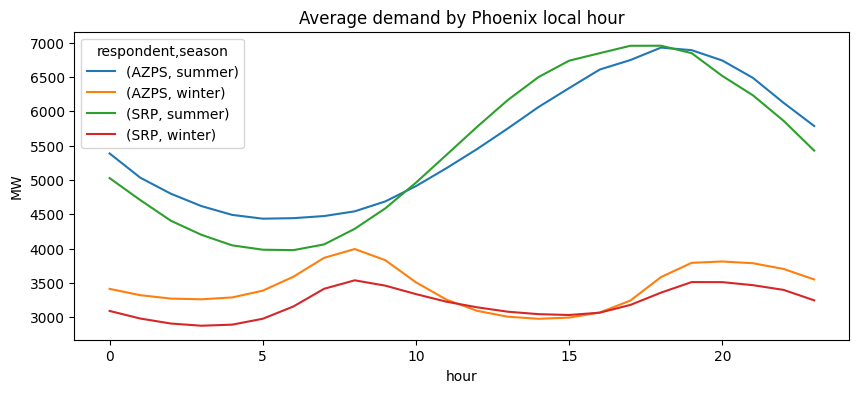

In [17]:
season = df["month"].map(lambda m: "summer" if m in (6, 7, 8) else ("winter" if m in (12, 1, 2) else None))
prof = (df.assign(season=season).dropna(subset=["season"])
          .groupby(["respondent", "season", "hour"])["demand_mw"].mean().unstack(["respondent", "season"]))
prof.plot(figsize=(10, 4), title="Average demand by Phoenix local hour"); plt.ylabel("MW"); plt.show()

**Cell 2:** Summer demand troughs near 5 AM and peaks at 5-6 PM (~6,950 MW). Winter is flat (3,000-4,000 MW) with small morning and evening bumps. Hour-of-day shape depends on season.

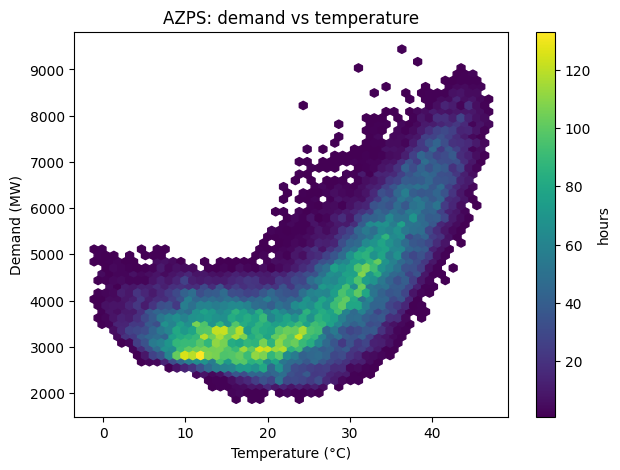

In [18]:
a = df[df["respondent"] == "AZPS"]
plt.figure(figsize=(7, 5))
plt.hexbin(a["temperature_2m"], a["demand_mw"], gridsize=50, cmap="viridis", mincnt=1)
plt.colorbar(label="hours"); plt.xlabel("Temperature (°C)"); plt.ylabel("Demand (MW)")
plt.title("AZPS: demand vs temperature"); plt.show()

**Cell 3:** Demand vs temperature is a hockey stick: flat up to ~20C, then rising steeply. This supports a cooling-degree-hours feature. The wide spread at each temperature means hour, humidity, sunlight and year also matter.

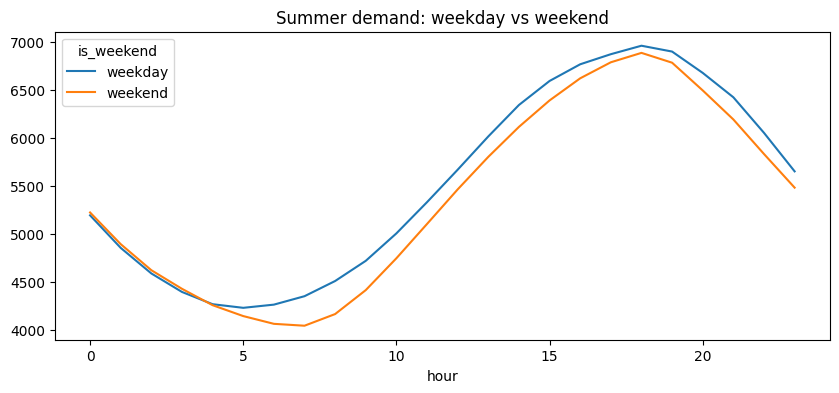

In [19]:
s = df[df["month"].isin([6, 7, 8])]
(s.groupby(["is_weekend", "hour"])["demand_mw"].mean().unstack(0)
   .rename(columns={False: "weekday", True: "weekend"})
   .plot(figsize=(10, 4), title="Summer demand: weekday vs weekend")); plt.show()

**Cell 4:** Weekdays run only ~100-350 MW above weekends, mostly during the morning ramp. Calendar features help a little, but the effect is small.

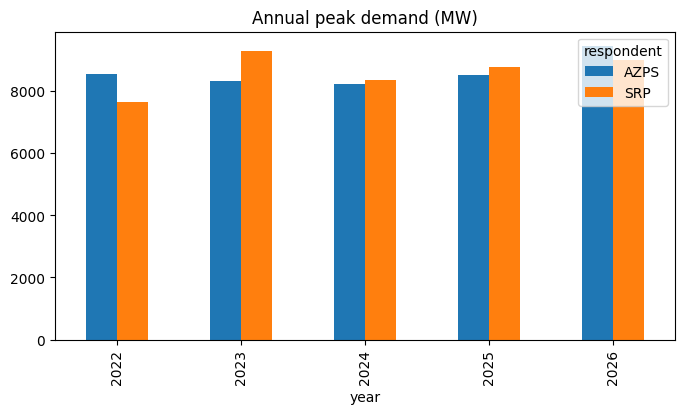

In [20]:
(df.groupby(["year", "respondent"])["demand_mw"].max().unstack()
   .plot(kind="bar", figsize=(8, 4), title="Annual peak demand (MW)")); plt.show()

**Cell 5:** Annual max is a poor growth measure because it depends on one hour. See Cells 7 and 8.

In [26]:
a = df[df["respondent"] == "AZPS"]

# 1) cool weather with very high demand is physically odd
odd = a[(a["temperature_2m"] < 20) & (a["demand_mw"] > 5500)]
print(len(odd), "cool-weather, high-demand hours")
print(odd[["period", "demand_mw", "temperature_2m", "was_repaired"]]
      .sort_values("demand_mw", ascending=False).head(15).to_string())

# 2) the highest reading overall, with 3 hours on each side
t = a.set_index("period")["demand_mw"].idxmax()
print(a.set_index("period").loc[t - pd.Timedelta(hours=3): t + pd.Timedelta(hours=3),
                                ["demand_mw", "temperature_2m"]])

0 cool-weather, high-demand hours
Empty DataFrame
Columns: [period, demand_mw, temperature_2m, was_repaired]
Index: []
                           demand_mw  temperature_2m
period                                              
2026-09-09 14:00:00+00:00     6654.0            31.0
2026-09-09 15:00:00+00:00     7524.0            32.8
2026-09-09 16:00:00+00:00     8701.0            34.5
2026-09-09 17:00:00+00:00     9437.0            36.0
2026-09-09 18:00:00+00:00     9426.0            36.3
2026-09-09 19:00:00+00:00     9139.0            38.1
2026-09-09 20:00:00+00:00     8510.0            39.3


**Cell 6:** Checked for physically odd readings (high demand in cool weather). Before the fix, 4 hours appeared, each next to an hour already flagged as a spike. Bad readings arrive in clusters and the edge hours slip past the 2x-median rule, so cleaning now also flags the hour before and after each flagged run (label "neighbor"). After the fix, 0 such hours remain. Cost: 161 of 83,463 hours (0.19%) are flagged only as neighbors. Most are probably fine and are now interpolated or excluded.

In [22]:
d = df[df["year"] >= 2022]
print(d.groupby(["year", "respondent"])["demand_mw"]
        .agg(mean="mean", p99=lambda s: s.quantile(0.99)).unstack().round(0))

              mean             p99        
respondent    AZPS     SRP    AZPS     SRP
year                                      
2022        3655.0  3706.0  6828.0  6859.0
2023        3835.0  3872.0  7676.0  7710.0
2024        4094.0  4070.0  7591.0  7729.0
2025        4437.0  4157.0  7702.0  7930.0
2026        5011.0  4361.0  8425.0  8113.0


**Cell 7:** Mean and 99th-percentile demand rose each year from 2022 to 2025 for both utilities. These measures don't depend on a single hour like the annual max does. 2026 covers only Jan-Oct 8 (no cool Nov-Dec), so its mean is biased upward and is not comparable to full years.

In [23]:
hot = d[d["temperature_2m"].between(38, 42) & d["hour"].between(16, 19)]
print(hot.groupby(["year", "respondent"])["demand_mw"].agg(["mean", "count"]).unstack().round(0))

              mean         count     
respondent    AZPS     SRP  AZPS  SRP
year                                 
2022        6194.0  6318.0   218  218
2023        6489.0  6699.0   175  175
2024        6748.0  6921.0   299  299
2025        6691.0  7074.0   212  214
2026        7173.0  6915.0   236  236


**Cell 8:** Like-for-like test: hot late afternoons only (38-42C, 4-7 PM local). At the same weather and hours, AZPS demand rose from 6,194 MW (2022) to 7,173 MW (2026), about +16%. SRP rose from 6,318 to 7,074 by 2025, then dipped in 2026. Same weather with more demand means structural growth (population, data centers). Implication: a model trained on early years will under-predict recent demand, so training should emphasize recent data and monitoring should watch for this drift.

In [24]:
for resp, g in demand.groupby("respondent"):
    s = g.set_index("period")["demand_mw"]
    print(resp, {f"{lag}h": round(s.autocorr(lag), 3) for lag in [1, 24, 48, 168]})

AZPS {'1h': np.float64(0.983), '24h': np.float64(0.962), '48h': np.float64(0.936), '168h': np.float64(0.894)}
SRP {'1h': np.float64(0.984), '24h': np.float64(0.961), '48h': np.float64(0.934), '168h': np.float64(0.892)}


**Cell 9:** Autocorrelation: 0.98 at 1h, 0.96 at 24h, 0.94 at 48h, 0.89 at 168h. Demand strongly resembles demand one day and one week earlier, which justifies lag features and means seasonal-naive baselines will be hard to beat. Part of this correlation is shared seasonality, so the real value of lags is measured by model error later. For a day-ahead forecast, only lags of 24h or more are available at prediction time, so features like the 1h lag must not be used (that would be leakage).

In [25]:
raw = pd.read_parquet("../data/raw/eia_2022-01-01_2026-10-08.parquet")
fc = (raw[(raw["type"] == "DF") & (raw["respondent"] == "AZPS")]
        .set_index("period")["value"].rename("utility_forecast"))

a = df[df["respondent"] == "AZPS"].set_index("period")
day = a.loc["2026-09-09 07:00":"2026-09-10 12:00", ["demand_mw", "temperature_2m"]].join(fc)
day["local_hour"] = day.index.tz_convert("America/Phoenix").hour
print(day.to_string())

# Same idea across all years: where does actual demand disagree wildly with the utility's forecast?
cmp = a[["demand_mw"]].join(fc, how="inner")
cmp["ratio"] = cmp["demand_mw"] / cmp["utility_forecast"]
print(cmp["ratio"].describe().round(2))
off = cmp[(cmp["ratio"] > 1.4) | (cmp["ratio"] < 0.7)]
print(len(off), "hours far from the utility forecast")
print(off.head(30).to_string())

                           demand_mw  temperature_2m  utility_forecast  local_hour
period                                                                            
2026-09-09 07:00:00+00:00    7250.00            36.0            5562.0           0
2026-09-09 08:00:00+00:00    7161.00            35.4            5590.0           1
2026-09-09 09:00:00+00:00    6681.00            34.5            5675.0           2
2026-09-09 10:00:00+00:00    6415.00            33.5            5624.0           3
2026-09-09 11:00:00+00:00    6373.00            33.0            5614.0           4
2026-09-09 12:00:00+00:00    6421.00            31.8            5604.0           5
2026-09-09 13:00:00+00:00    6382.00            31.0            5581.0           6
2026-09-09 14:00:00+00:00    6654.00            31.0            5631.0           7
2026-09-09 15:00:00+00:00    7524.00            32.8            5615.0           8
2026-09-09 16:00:00+00:00    8701.00            34.5            5774.0           9
2026

**Cell 10:** Compared actual AZPS demand with the utility's day-ahead forecast. Overall the forecast is a good reference: median actual/forecast = 1.01, middle half 0.98-1.07, and only 174 of 41,330 hours (0.4%) fall outside 0.7-1.4. Those outliers cluster on specific days (Sept 2023, Feb 12-13 2025), which points to events or feed problems rather than random noise. The overall max (9,437 MW, 2026-09-09, 10 AM local) is 1.59x the forecast, and demand falls through the afternoon while temperature rises, which is physically odd. Rule: forecast disagreement is used to investigate, never to remove hours from evaluation, because that would flatter the benchmark.

In [27]:
raw = pd.read_parquet("../data/raw/eia_2022-01-01_2026-10-08.parquet")
fc_all = (raw[raw["type"] == "DF"].set_index(["respondent", "period"])["value"]
             .rename("utility_forecast"))

# 1) Monthly median of actual / forecast, per utility
x = (df.set_index(["respondent", "period"])[["demand_mw"]]
       .join(fc_all, how="inner").reset_index())
x["ratio"] = x["demand_mw"] / x["utility_forecast"]
x["ym"] = x["period"].dt.tz_convert("America/Phoenix").dt.strftime("%Y-%m")
print(x.groupby(["ym", "respondent"])["ratio"].median().unstack().round(3).tail(24))

# 2) Did SRP see the same odd morning on 2026-09-09?
srp = df[df["respondent"] == "SRP"].set_index("period")
day = srp.loc["2026-09-09 07:00":"2026-09-10 06:00", ["demand_mw"]].join(
    fc_all.xs("SRP", level="respondent"))
day["ratio"] = (day["demand_mw"] / day["utility_forecast"]).round(2)
day["local_hour"] = day.index.tz_convert("America/Phoenix").hour
print(day.to_string())

respondent   AZPS    SRP
ym                      
2024-11     1.011  1.026
2024-12     1.022  1.022
2025-01     1.009  1.027
2025-02     1.183  1.045
2025-03     1.128  1.037
2025-04     1.023  1.034
2025-05     1.019  1.024
2025-06     1.041  1.032
2025-07     1.032  1.028
2025-08     1.051  1.021
2025-09     1.099  1.023
2025-10     1.123  1.028
2025-11     1.144  1.030
2025-12     1.168  1.008
2026-01     1.136  1.022
2026-02     1.121  1.034
2026-03     1.057  0.980
2026-04     0.972  0.867
2026-05     1.007  0.797
2026-06     1.012  0.968
2026-07     1.026  0.955
2026-08     1.026  0.947
2026-09     1.090  0.923
2026-10     1.100  0.932
                           demand_mw  utility_forecast  ratio  local_hour
period                                                                   
2026-09-09 07:00:00+00:00     5467.0            5656.0   0.97           0
2026-09-09 08:00:00+00:00     4877.0            5430.0   0.90           1
2026-09-09 09:00:00+00:00     4642.0            5163.0

**Cell 11:** Compared the actual/forecast ratio by month for each utility. Both sit near 1.01-1.05 through mid-2025. After that they diverge: AZPS runs 10-17% above its forecast from Sep 2025 to Feb 2026 (and 9-10% in Sep-Oct 2026), while SRP falls below its forecast in 2026 (as low as 0.80 in May 2026). Feb 2025 was also high for AZPS (1.18), so that episode lasted most of a month, not just two days. SRP showed no morning surge on 2026-09-09 (ratio 1.05 at 10 AM local, versus 1.59 for AZPS), so that AZPS anomaly is specific to AZPS and not a regional event. I can't tell from this data whether the shifts are real load changes or reporting changes. Decision: keep all hours, because removing hours based on forecast disagreement would flatter the benchmark. Evaluate with and without the suspect periods later, and expect the utility forecast to look worse in these months.